# From one weight to handwritten digits: backpropagation from scratch

This notebook builds a neural network from nothing but Python arithmetic, in four steps:

1. **One weight.** What a gradient is, and why the chain rule is all backpropagation needs.
2. **A tiny network.** One input, two hidden nodes, one output. Why a step activation can't learn, and what fixes it.
3. **Matrices.** The same chain rule written for hundreds of weights at once, trained on images of handwritten digits.
4. **What a hidden layer buys you.** A linear model does surprisingly well, until it doesn't.

Nothing here uses a machine-learning library. Everything you need is plain Python, NumPy for Part 3 onwards, and `matplotlib` for pictures.

**Exercises** are marked in bold. Solution cells are tagged `solution`, so an instructor can strip them to produce the student version, e.g. with

    jupyter nbconvert --to notebook --TagRemovePreprocessor.remove_cell_tags=solution backprop.ipynb

In [42]:
import math, random
import numpy as np
import matplotlib.pyplot as plt
import vscodenb
#plt.rcParams["figure.figsize"] = (6, 3.5)

## Part 1: One weight

### Background

A model is a function with knobs. The smallest possible one is

$$y = w\,x + b$$

with two knobs, $w$ and $b$. For a given input $x$ we would like the output $y$ to be close to a target $t$. We measure how far off we are with a **loss**:

$$L = (y - t)^2$$

Learning means turning the knobs to make $L$ smaller. The only question is: which way should each knob turn, and by how much?

### The gradient is "nudge and see"

Take $w$. If we nudge it by a tiny amount $h$ and recompute the loss, the loss changes by some amount. The ratio

$$\frac{L(w+h) - L(w)}{h}$$

tells us how much the loss changes *per unit change in $w$*. If it is positive, increasing $w$ makes things worse, so we should decrease $w$. If it is negative, increase $w$. That ratio is the **gradient** of the loss with respect to $w$. There is nothing more to it.

In [2]:
x, t = 2.0, 7.0            # one input and its target
w, b = 0.5, 0.0            # starting values of the knobs

def loss(w, b):
    y = w*x + b
    return (y - t)**2

h = 1e-4
grad_w_numerical = (loss(w + h, b) - loss(w, b)) / h
grad_b_numerical = (loss(w, b + h) - loss(w, b)) / h
print("dL/dw ≈", round(grad_w_numerical, 3))
print("dL/db ≈", round(grad_b_numerical, 3))

dL/dw ≈ -24.0
dL/db ≈ -12.0


### The chain rule gives the same number

Nudging works, but it needs two extra loss evaluations per knob. With a million knobs that is a million extra passes through the model. Calculus gives us the same number for free.

The loss depends on $w$ only *through* $y$. So

$$\frac{dL}{dw} = \frac{dL}{dy}\cdot\frac{dy}{dw}$$

Each factor is easy on its own:

- $\dfrac{dL}{dy} = 2(y - t)$: the derivative of a square.
- $\dfrac{dy}{dw} = x$: the derivative of $w x + b$ with respect to $w$.
- $\dfrac{dy}{db} = 1$.

So $\dfrac{dL}{dw} = 2(y-t)\,x$ and $\dfrac{dL}{db} = 2(y-t)$.

This is the whole idea of backpropagation: **start at the loss, walk backwards through the computation, multiply the local derivatives as you go.** Everything that follows is this, repeated.

In [3]:
y = w*x + b
dL_dy = 2*(y - t)           # start at the loss
grad_w = dL_dy * x          # one step back to w
grad_b = dL_dy * 1          # one step back to b
print("chain rule:  dL/dw =", grad_w, "   dL/db =", grad_b)
print("numerical :  dL/dw ≈", round(grad_w_numerical, 3), "   dL/db ≈", round(grad_b_numerical, 3))

chain rule:  dL/dw = -24.0    dL/db = -12.0
numerical :  dL/dw ≈ -24.0    dL/db ≈ -12.0


### Training is "take a small step downhill, repeat"

Once we know the gradient we move each knob a small step in the opposite direction. The step size is called the **learning rate**, usually written `lr`.

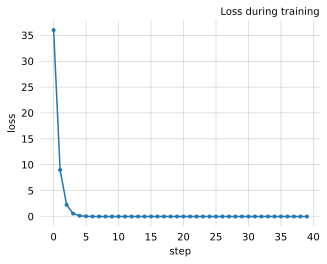

after training: w = 2.900, b = 1.200, y = 7.000  (target 7.0)


In [4]:
w, b, lr = 0.5, 0.0, 0.05
history = []
for step in range(40):
    y = w*x + b                 # forward
    L = (y - t)**2
    dL_dy = 2*(y - t)           # backward
    w -= lr * dL_dy * x         # update
    b -= lr * dL_dy
    history.append(L)

plt.plot(history, marker=".")
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Loss during training")
plt.show()
print(f"after training: w = {w:.3f}, b = {b:.3f}, y = {w*x + b:.3f}  (target {t})")

**Exercise 1.1.** Set `lr = 0.3` and run the training loop again. What happens, and why? (Think about what the update does when the gradient is large.)

**Exercise 1.2.** There are infinitely many pairs $(w, b)$ that give $y = 7$ when $x = 2$. Which one did training find? Does it depend on the starting values? Try starting from `w, b = 5.0, -1.0`.

In [5]:
# Solution 1.1
w, b, lr = 0.5, 0.0, 0.3
for step in range(8):
    y = w*x + b
    dL_dy = 2*(y - t)
    w -= lr * dL_dy * x
    b -= lr * dL_dy
    print(f"step {step}: loss = {(y-t)**2:.1f}")
# The loss grows instead of shrinking: with lr=0.3 and x=2, each step overshoots
# the minimum and lands further away on the other side. The learning rate must be
# small relative to how steep the loss is.

step 0: loss = 36.0
step 1: loss = 144.0
step 2: loss = 576.0
step 3: loss = 2304.0
step 4: loss = 9216.0
step 5: loss = 36864.0
step 6: loss = 147456.0
step 7: loss = 589824.0


In [6]:
# Solution 1.2
for w0, b0 in [(0.5, 0.0), (5.0, -1.0)]:
    w, b, lr = w0, b0, 0.05
    for step in range(200):
        y = w*x + b
        dL_dy = 2*(y - t)
        w -= lr * dL_dy * x
        b -= lr * dL_dy
    print(f"start ({w0}, {b0}) -> w = {w:.3f}, b = {b:.3f}, y = {w*x+b:.3f}")
# Both reach y = 7 but at different (w, b). With one data point the problem is
# underdetermined; gradient descent stops at the first solution it hits, which
# depends on where it started. More data points pin the solution down.

start (0.5, 0.0) -> w = 2.900, b = 1.200, y = 7.000
start (5.0, -1.0) -> w = 4.200, b = -1.400, y = 7.000


## Part 2: A tiny network

### Background

A single weight can only draw a straight line. To draw anything more interesting we put a **non-linear function** between layers. The simplest is the step function:

$$\mathrm{step}(z) = \begin{cases}1 & z \ge 0\\ 0 & z < 0\end{cases}$$

Our network has one input $x$, two hidden nodes, and one linear output:

$$h_1 = \mathrm{step}(w_1 x + b_1),\qquad h_2 = \mathrm{step}(w_2 x + b_2),\qquad y = v_1 h_1 + v_2 h_2 + c$$

Each hidden node is a switch that flips on when $x$ passes a threshold ($x = -b_i / w_i$ when $w_i = 1$). The output adds up the switches that are on.

### The target: a staircase

We want the network to reproduce this curve:

$$t(x) = \begin{cases} 0 & x < 1 \\ 2 & 1 \le x < 3 \\ 1 & x \ge 3\end{cases}$$

Before running anything, convince yourself that the network *can* do it: switch 1 turns on at $x=1$ and contributes $+2$; switch 2 turns on at $x=3$ and contributes $-1$; the bias $c$ is $0$.

In [7]:
def step(z):
    return 1.0 if z >= 0 else 0.0

def target(x):
    if x < 1: return 0.0
    if x < 3: return 2.0
    return 1.0

xs = [i / 10 for i in range(0, 50)]     # x from 0.0 to 4.9

def plot_fit(net, title):
    plt.step(xs, [target(x) for x in xs], where="post", label="target", lw=3, alpha=.4)
    plt.plot(xs, [net(x) for x in xs], label="network")
    plt.xlabel("x"); plt.ylabel("y"); plt.title(title); plt.legend(); plt.show()

### Part 2A: hand-set thresholds, learn the output weights

We fix the two switches at the right thresholds and let the network learn only $v_1, v_2, c$. Because the switches are just fixed on/off numbers, the gradient to the output weights is exactly the Part 1 formula: $\frac{dL}{dv_1} = 2(y-t)\,h_1$, and so on.

v1 = 2.00, v2 = -1.00, c = 0.00   (expected 2, -1, 0)


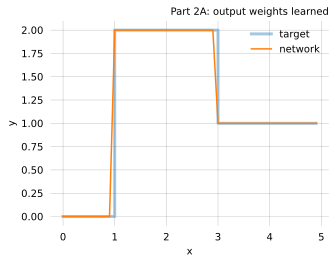

In [8]:
w1, b1 = 1.0, -1.0          # switch 1 turns on at x = 1
w2, b2 = 1.0, -3.0          # switch 2 turns on at x = 3
v1, v2, c = 0.0, 0.0, 0.0   # to be learned
lr = 0.05

for epoch in range(100):
    for x in xs:
        h1 = step(w1*x + b1)           # forward
        h2 = step(w2*x + b2)
        y = v1*h1 + v2*h2 + c
        dL_dy = 2*(y - target(x))      # backward
        v1 -= lr * dL_dy * h1          # dy/dv1 = h1
        v2 -= lr * dL_dy * h2          # dy/dv2 = h2
        c  -= lr * dL_dy               # dy/dc  = 1

print(f"v1 = {v1:.2f}, v2 = {v2:.2f}, c = {c:.2f}   (expected 2, -1, 0)")
plot_fit(lambda x: v1*step(w1*x+b1) + v2*step(w2*x+b2) + c, "Part 2A: output weights learned")

### Part 2B: try to learn the thresholds too

Now suppose we don't know where the switches should be. We want to learn $w_1, b_1$ as well. The chain from the loss to $b_1$ has one more link than before, because the loss depends on $b_1$ through $z_1 = w_1 x + b_1$, then through $h_1 = \mathrm{step}(z_1)$, then through $y$:

$$\frac{dL}{db_1} = \frac{dL}{dy}\cdot\frac{dy}{dh_1}\cdot\frac{dh_1}{dz_1}\cdot\frac{dz_1}{db_1} = 2(y-t)\cdot v_1 \cdot \mathrm{step}'(z_1)\cdot 1$$

**Exercise 2.1.** What is $\mathrm{step}'(z)$, the slope of the step function, for $z \ne 0$? What does that mean for the product above?

Let's start switch 1 in the wrong place ($b_1 = -2$) and watch what happens.

b1 = -2.00  (it started at -2.00 and never moved)


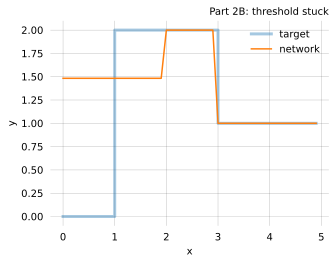

In [9]:
def dstep(z):
    return 0.0          # the step function is flat everywhere except at z = 0

w1, b1 = 1.0, -2.0      # wrong: switch 1 turns on at x = 2 instead of 1
w2, b2 = 1.0, -3.0
v1, v2, c = 0.0, 0.0, 0.0

for epoch in range(100):
    for x in xs:
        z1, z2 = w1*x + b1, w2*x + b2
        h1, h2 = step(z1), step(z2)
        y = v1*h1 + v2*h2 + c
        dL_dy = 2*(y - target(x))
        dz1 = dL_dy * v1 * dstep(z1)      # the extra link in the chain
        v1 -= lr*dL_dy*h1;  v2 -= lr*dL_dy*h2;  c -= lr*dL_dy
        w1 -= lr*dz1*x;     b1 -= lr*dz1

print(f"b1 = {b1:.2f}  (it started at -2.00 and never moved)")
plot_fit(lambda x: v1*step(w1*x+b1) + v2*step(w2*x+b2) + c, "Part 2B: threshold stuck")

In [10]:
# Solution 2.1
# step'(z) = 0 for every z != 0 (and undefined at z = 0). So dL/db1 is always
# 2(y-t) * v1 * 0 = 0: the loss is blind to small changes in b1. Gradient descent
# only sees slopes, and a staircase has none. The output weights did their best
# with the switch in the wrong place, which is why the fit is poor around x = 1..2.

### Part 2C: replace the step with something that has a slope

The fix is to use a smooth version of the step, the **sigmoid**:

$$\sigma_k(z) = \frac{1}{1 + e^{-kz}}$$

For large $k$ it looks almost exactly like a step, but its slope is never zero:

$$\sigma_k'(z) = k\,\sigma_k(z)\,(1 - \sigma_k(z))$$

Now every link in the chain is non-zero and the thresholds can move.

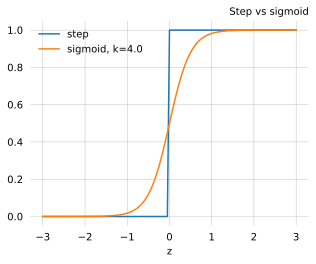

In [11]:
k = 4.0
def sig(z):  return 1 / (1 + math.exp(-k*z))
def dsig(z): a = sig(z); return k * a * (1 - a)

zs = [i/20 for i in range(-60, 61)]
plt.plot(zs, [step(z) for z in zs], label="step")
plt.plot(zs, [sig(z) for z in zs], label=f"sigmoid, k={k}")
plt.legend(); plt.xlabel("z"); plt.title("Step vs sigmoid"); plt.show()

starting thresholds: 0.67, 4.24
learned thresholds:  0.95, 2.88   (expected 1 and 3)


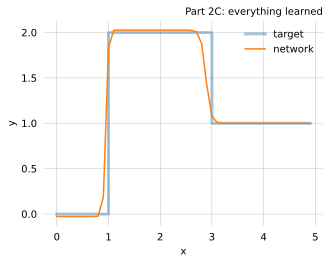

In [12]:
random.seed(1)
w1, b1 = 1.0, -random.uniform(0, 5)     # random starting thresholds
w2, b2 = 1.0, -random.uniform(0, 5)
v1, v2, c = 0.0, 0.0, 0.0
print(f"starting thresholds: {-b1/w1:.2f}, {-b2/w2:.2f}")

for epoch in range(3000):
    for x in xs:
        z1, z2 = w1*x + b1, w2*x + b2      # forward
        h1, h2 = sig(z1), sig(z2)
        y = v1*h1 + v2*h2 + c
        dL_dy = 2*(y - target(x))          # backward
        dz1 = dL_dy * v1 * dsig(z1)
        dz2 = dL_dy * v2 * dsig(z2)
        v1 -= lr*dL_dy*h1;  v2 -= lr*dL_dy*h2;  c -= lr*dL_dy
        w1 -= lr*dz1*x;     b1 -= lr*dz1
        w2 -= lr*dz2*x;     b2 -= lr*dz2

print(f"learned thresholds:  {-b1/w1:.2f}, {-b2/w2:.2f}   (expected 1 and 3)")
plot_fit(lambda x: v1*sig(w1*x+b1) + v2*sig(w2*x+b2) + c, "Part 2C: everything learned")

**Exercise 2.2.** Design the weights by hand (no training) for a different target: $t(x) = 1$ for $1 \le x < 3$ and $0$ otherwise. Check your answer with `plot_fit`.

**Exercise 2.3.** In Part 2C, try `k = 1.0` and `k = 20.0`. Which trains better, and what does the fitted curve look like in each case? What does this suggest about the trade-off between "looks like a step" and "has a usable slope"?

**Exercise 2.4.** Add a third hidden node and find a target curve that needs it.

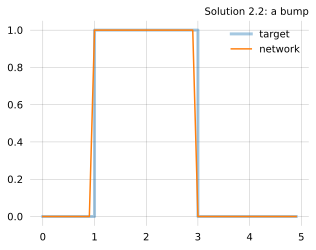

In [13]:
# Solution 2.2
# Switch on at x=1 contributing +1, switch on at x=3 contributing -1, bias 0.
w1_, b1_, w2_, b2_, v1_, v2_, c_ = 1.0, -1.0, 1.0, -3.0, 1.0, -1.0, 0.0
def target2(x): return 1.0 if 1 <= x < 3 else 0.0
plt.step(xs, [target2(x) for x in xs], where="post", lw=3, alpha=.4, label="target")
plt.plot(xs, [v1_*step(w1_*x+b1_) + v2_*step(w2_*x+b2_) + c_ for x in xs], label="network")
plt.legend(); plt.title("Solution 2.2: a bump"); plt.show()

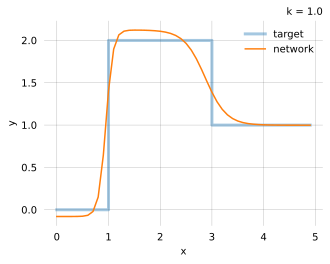

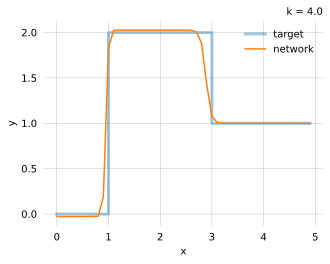

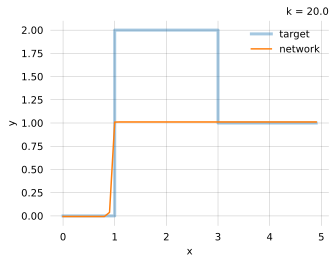

In [14]:
# Solution 2.3
def train_1_2_1(k, epochs=3000, seed=1):
    def sig(z):  return 1 / (1 + math.exp(-k*z))
    def dsig(z): a = sig(z); return k*a*(1-a)
    random.seed(seed)
    w1, b1, w2, b2 = 1.0, -random.uniform(0, 5), 1.0, -random.uniform(0, 5)
    v1 = v2 = c = 0.0
    for epoch in range(epochs):
        for x in xs:
            z1, z2 = w1*x+b1, w2*x+b2; h1, h2 = sig(z1), sig(z2)
            y = v1*h1 + v2*h2 + c; d = 2*(y - target(x))
            dz1, dz2 = d*v1*dsig(z1), d*v2*dsig(z2)
            v1 -= lr*d*h1; v2 -= lr*d*h2; c -= lr*d
            w1 -= lr*dz1*x; b1 -= lr*dz1; w2 -= lr*dz2*x; b2 -= lr*dz2
    return lambda x: v1*sig(w1*x+b1) + v2*sig(w2*x+b2) + c

for k_ in [1.0, 4.0, 20.0]:
    plot_fit(train_1_2_1(k_), f"k = {k_}")
# k=1: trains easily but the curve is too soft to look like a staircase.
# k=20: looks like a step but the slope is ~0 almost everywhere, so the thresholds
# barely move unless they start near the right place (compare the failure in 2B).
# k=4 is a compromise. In practice networks use k=1 and let the weights w grow.

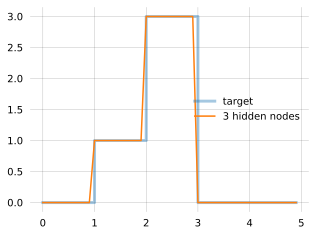

In [15]:
# Solution 2.4 (one possibility)
# A target with three levels that go up, up, down needs two "on" switches and one
# "off" switch, e.g. t = 0 (x<1), 1 (1<=x<2), 3 (2<=x<3), 0 (x>=3).
# Hand-set: thresholds 1, 2, 3 with v = +1, +2, -3 and c = 0.
def target3(x):
    if x < 1: return 0.0
    if x < 2: return 1.0
    if x < 3: return 3.0
    return 0.0
net3 = lambda x: 1*step(x-1) + 2*step(x-2) - 3*step(x-3)
plt.step(xs, [target3(x) for x in xs], where="post", lw=3, alpha=.4, label="target")
plt.plot(xs, [net3(x) for x in xs], label="3 hidden nodes"); plt.legend(); plt.show()
# Two switches can only make two jumps, so this target is impossible for the 1-2-1 network.

## Part 3: Matrices, and real data

### Background

The toy network has 7 numbers to learn. A network that reads an image has thousands, and a `for` loop over every weight in Python would take hours per pass. The fix is not a new idea but new notation: write the layer as a **matrix product**.

If the input is a row vector $\mathbf{x}$ with $n$ pixels, and the hidden layer has $m$ nodes, then all $m$ pre-activations at once are

$$\mathbf{z}_1 = \mathbf{x} W_1 + \mathbf{b}_1,\qquad \mathbf{h} = \sigma(\mathbf{z}_1),\qquad \mathbf{z}_2 = \mathbf{h} W_2 + \mathbf{b}_2$$

where $W_1$ is an $n\times m$ matrix and $W_2$ is $m \times 10$. NumPy does this with `x @ W1 + b1`, and it does it for a whole batch of images at once if `x` has one row per image.

### Ten outputs instead of one

We want to classify a digit as one of 10 classes, so the network has 10 output nodes. Instead of a squared error we use **softmax** to turn the 10 outputs into probabilities,

$$p_j = \frac{e^{z_j}}{\sum_i e^{z_i}}$$

and the **cross-entropy** loss $L = -\log p_{\text{correct}}$, which punishes putting low probability on the right answer. The reason to accept these two new formulas is that their combined gradient is remarkably simple:

$$\frac{\partial L}{\partial \mathbf{z}_2} = \mathbf{p} - \mathbf{t}$$

where $\mathbf{t}$ is the one-hot target vector (a 1 in the correct slot, 0 elsewhere). This is "output minus target", the same thing as the $2(y-t)$ we have used throughout, just without the factor 2.

### Backpropagation through a matrix layer

The chain rule works the same, but the local derivatives become matrix transposes. For a layer $\mathbf{z} = \mathbf{h} W + \mathbf{b}$ with gradient $\delta = \partial L/\partial\mathbf{z}$ arriving from above:

| quantity | scalar version (Part 2) | matrix version |
|---|---|---|
| gradient to the weights | `dz * h` | `h.T @ dz` |
| gradient to the bias | `dz` | `dz.sum(axis=0)` |
| gradient passed back to $\mathbf{h}$ | `dz * v` | `dz @ W.T` |
| through the sigmoid | `dh * dsig(z)` | `dh * h * (1 - h)` |

Each line is one of the toy-network lines, with every number replaced by an array.

### The data

`scikit-learn` ships with a small handwritten-digit dataset: 1797 images of 8×8 pixels, each labelled 0–9. It needs no download and trains in seconds, which makes it ideal for experimenting. (A section at the end shows how to switch to the full-size MNIST data.)

images: (1797, 8, 8)   labels: (1797,)


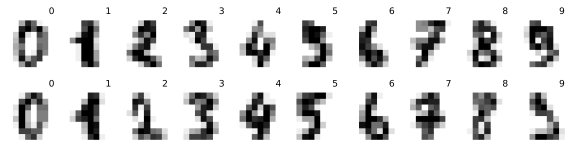

X_train: (1347, 64)   X_test: (450, 64)


In [16]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
images = digits.images / 16.0        # pixel values 0..16 -> 0..1
labels = digits.target
print("images:", images.shape, "  labels:", labels.shape)

fig, axes = plt.subplots(2, 10, figsize=(10, 2.4))
for ax, im, lab in zip(axes.ravel(), images, labels):
    ax.imshow(im, cmap="gray_r"); ax.set_title(lab, fontsize=9); ax.axis("off")
plt.show()

# Hold out a quarter of the data that the network never sees during training.
img_train, img_test, y_train, y_test = train_test_split(
    images, labels, test_size=0.25, random_state=0, stratify=labels)
X_train = img_train.reshape(len(img_train), -1)     # each 8x8 image -> row of 64 numbers
X_test  = img_test.reshape(len(img_test), -1)
print("X_train:", X_train.shape, "  X_test:", X_test.shape)

### The network as a few functions

We write one `train` function that handles both a network **with** a hidden layer and one **without** (`n_hidden=0`), so that we can compare them fairly later. Read the backward pass line by line against the table above.

In [17]:
def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))   # subtract max: avoids overflow, same result
    return e / e.sum(axis=1, keepdims=True)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def train(X, y, n_hidden=0, epochs=200, lr=0.5, batch=32, seed=0, X_val=None, y_val=None):
    "Train a 1-hidden-layer network (or a linear model if n_hidden=0). Returns the parameters."
    rng = np.random.default_rng(seed)
    n_in, n_out = X.shape[1], 10
    T = np.eye(n_out)[y]                            # one-hot targets, one row per image
    if n_hidden:
        W1 = rng.normal(0, 1/np.sqrt(n_in), (n_in, n_hidden)); b1 = np.zeros(n_hidden)
        W2 = rng.normal(0, 1/np.sqrt(n_hidden), (n_hidden, n_out)); b2 = np.zeros(n_out)
    else:
        W1 = b1 = None
        W2 = rng.normal(0, 1/np.sqrt(n_in), (n_in, n_out)); b2 = np.zeros(n_out)

    history = []
    for epoch in range(epochs):
        order = rng.permutation(len(X))              # shuffle, then go through in small batches
        for i in range(0, len(X), batch):
            idx = order[i:i+batch]
            x, t = X[idx], T[idx]
            # ---- forward ----
            if n_hidden:
                h = sigmoid(x @ W1 + b1)
            else:
                h = x
            p = softmax(h @ W2 + b2)
            # ---- backward ----
            dz2 = (p - t) / len(idx)                 # "output minus target", averaged over the batch
            dW2 = h.T @ dz2                          # was  dz * h
            db2 = dz2.sum(axis=0)                    # was  dz
            if n_hidden:
                dh  = dz2 @ W2.T                     # was  dz * v
                dz1 = dh * h * (1 - h)               # through the sigmoid
                dW1 = x.T @ dz1
                db1 = dz1.sum(axis=0)
            # ---- update ----
            W2 -= lr * dW2;  b2 -= lr * db2
            if n_hidden:
                W1 -= lr * dW1;  b1 -= lr * db1
        if X_val is not None:
            history.append(accuracy((W1, b1, W2, b2), X_val, y_val))
    params = (W1, b1, W2, b2)
    return (params, history) if X_val is not None else params

def predict(params, X):
    W1, b1, W2, b2 = params
    h = sigmoid(X @ W1 + b1) if W1 is not None else X
    return softmax(h @ W2 + b2).argmax(axis=1)

def accuracy(params, X, y):
    return (predict(params, X) == y).mean()

### Train both models

First the **linear model**: 64 pixels straight to 10 outputs, no hidden layer. Then the same with **32 hidden nodes**.

linear model  : train 0.997   test 0.967
32 hidden     : train 1.000   test 0.978


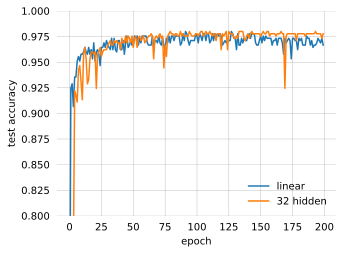

In [18]:
linear, hist_lin = train(X_train, y_train, n_hidden=0,  X_val=X_test, y_val=y_test)
hidden, hist_hid = train(X_train, y_train, n_hidden=32, X_val=X_test, y_val=y_test)

print(f"linear model  : train {accuracy(linear, X_train, y_train):.3f}   test {accuracy(linear, X_test, y_test):.3f}")
print(f"32 hidden     : train {accuracy(hidden, X_train, y_train):.3f}   test {accuracy(hidden, X_test, y_test):.3f}")

plt.plot(hist_lin, label="linear"); plt.plot(hist_hid, label="32 hidden")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.ylim(0.8, 1); plt.legend(); plt.show()

Both are around 97 %. That is a real network recognising real handwriting, written from scratch in a few dozen lines. But it also raises a question: **if the linear model is this good, what is the hidden layer for?**

### What the linear model has learned

A linear model's weights for class $j$ are a vector with one entry per pixel. Reshape it to 8×8 and it is an image: a **template**. Positive weights (dark) where that digit usually has ink, negative (light) where it usually doesn't.

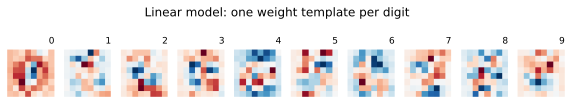

In [19]:
W = linear[2]
fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for j, ax in enumerate(axes):
    ax.imshow(W[:, j].reshape(8, 8), cmap="RdBu_r"); ax.set_title(j, fontsize=9); ax.axis("off")
plt.suptitle("Linear model: one weight template per digit", y=1.15); plt.show()

The linear model classifies by asking "which template does this image correlate with best?" On centred, size-normalised digits that works most of the time. What it cannot express is a rule like *"ink here means 9, unless there is also ink there, in which case 4"*. That needs an AND of features, which is a non-linear operation.

**Exercise 3.1.** Show the test digits that the linear model gets wrong, with the true and predicted labels. Are they the pairs you would expect to be confused?

**Exercise 3.2.** Train with `n_hidden` equal to 4, 8, 16, 64. How does test accuracy depend on the number of hidden nodes? Is more always better?

**Exercise 3.3.** The `train` function computes `dz2 = (p - t) / len(idx)`, the gradient *averaged* over the batch. Remove the division and retrain. After Exercise 1.1 you might expect the 32-times-larger steps to make training diverge. Does it? Why not? (Hint: how large can an entry of `p - t` be? How large could `2*(y - t)` get in Part 1?)

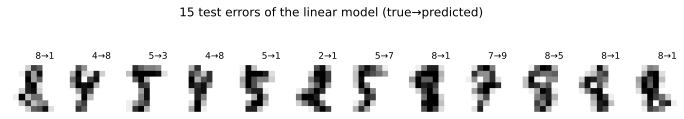

In [20]:
# Solution 3.1
pred = predict(linear, X_test)
wrong = np.where(pred != y_test)[0]
fig, axes = plt.subplots(1, min(12, len(wrong)), figsize=(12, 1.6))
for ax, i in zip(axes, wrong):
    ax.imshow(img_test[i], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"{y_test[i]}→{pred[i]}", fontsize=9)
plt.suptitle(f"{len(wrong)} test errors of the linear model (true→predicted)", y=1.2); plt.show()
# Most confusions are between digits that share strokes: 1/7, 4/9, 3/5/8, 2/7.

In [21]:
# Solution 3.2
for nh in [4, 8, 16, 32, 64]:
    p_ = train(X_train, y_train, n_hidden=nh)
    print(f"{nh:3d} hidden: test accuracy {accuracy(p_, X_test, y_test):.3f}")
# Very few hidden nodes act as a bottleneck and hurt. Beyond ~16 the gain flattens
# out on this easy dataset; extra capacity mostly memorises the training set.

  4 hidden: test accuracy 0.847
  8 hidden: test accuracy 0.971
 16 hidden: test accuracy 0.971
 32 hidden: test accuracy 0.978
 64 hidden: test accuracy 0.976


In [22]:
# Solution 3.3
p_sum = train(X_train, y_train, n_hidden=0)                 # mean gradient (as written)
# ... and a copy of train() with "/ len(idx)" removed would give the summed gradient.
# It does NOT diverge: it reaches about the same test accuracy. The reason is that
# p and t are both probabilities, so every entry of p - t lies between -1 and 1 no
# matter how wrong the network is. The squared-error gradient 2(y - t) in Part 1
# had no such bound, which is what let it run away. The summed version is simply
# running with an effective learning rate 32 times larger, which is noisier and
# would matter more with a bigger batch. Averaging is the convention because it
# keeps the right learning rate independent of the batch size.

## Part 4: When template matching stops working

### Background

The linear model did well because every digit sits in the same place in the frame. Templates only work when the ink is where the template expects it. Let's break that assumption: paste each 8×8 digit at a **random position** inside a 12×12 frame. The digits are the same; only their location varies. A human would not notice a difference in difficulty.

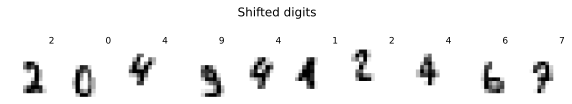

training images: (5388, 144)


In [23]:
def shift_images(imgs, size=12, rng=None):
    "Paste each 8x8 image at a random offset inside a size x size frame."
    rng = rng or np.random.default_rng(0)
    out = np.zeros((len(imgs), size, size))
    for k, im in enumerate(imgs):
        r, c = rng.integers(0, size - 8 + 1, 2)
        out[k, r:r+8, c:c+8] = im
    return out

rng = np.random.default_rng(1)
# Training set: each image pasted at 4 different random positions (data augmentation).
img_train_s = np.vstack([shift_images(img_train, rng=rng) for _ in range(4)])
y_train_s   = np.tile(y_train, 4)
img_test_s  = shift_images(img_test, rng=rng)

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, im, lab in zip(axes, img_test_s, y_test):
    ax.imshow(im, cmap="gray_r"); ax.set_title(lab, fontsize=9); ax.axis("off")
plt.suptitle("Shifted digits", y=1.15); plt.show()

Xs_train = img_train_s.reshape(len(img_train_s), -1)
Xs_test  = img_test_s.reshape(len(img_test_s), -1)
print("training images:", Xs_train.shape)

linear model  : test 0.296
64 hidden     : test 0.922


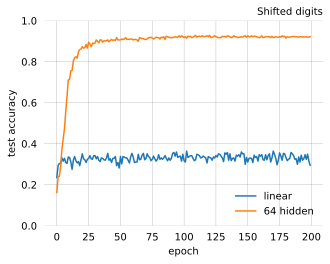

In [24]:
linear_s, hist_lin_s = train(Xs_train, y_train_s, n_hidden=0,  X_val=Xs_test, y_val=y_test)
hidden_s, hist_hid_s = train(Xs_train, y_train_s, n_hidden=64, X_val=Xs_test, y_val=y_test)

print(f"linear model  : test {accuracy(linear_s, Xs_test, y_test):.3f}")
print(f"64 hidden     : test {accuracy(hidden_s, Xs_test, y_test):.3f}")

plt.plot(hist_lin_s, label="linear"); plt.plot(hist_hid_s, label="64 hidden")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.ylim(0, 1); plt.legend()
plt.title("Shifted digits"); plt.show()

Same digits, same training code, same amount of data. The linear model collapses to around 30 % because no single template can match a "3" in sixteen different places at once; the templates blur into mush. The network with a hidden layer loses a few points and carries on.

Why? Look at what the hidden nodes have become.

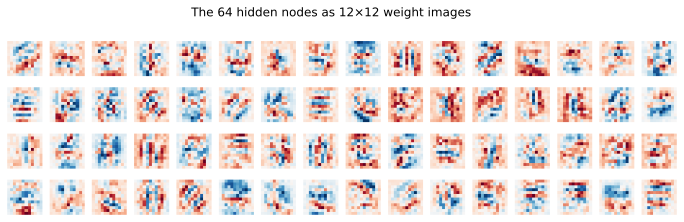

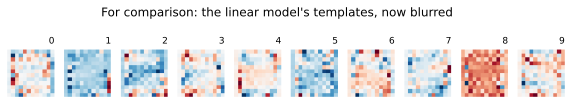

In [44]:
W1 = hidden_s[0]
fig, axes = plt.subplots(4, 16, figsize=(12, 3.2))
for j, ax in enumerate(axes.ravel()):
    ax.imshow(W1[:, j].reshape(12, 12), cmap="RdBu_r"); ax.axis("off")
plt.suptitle("The 64 hidden nodes as 12×12 weight images", y=1.02); plt.show()

W_lin = linear_s[2]
fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for j, ax in enumerate(axes):
    ax.imshow(W_lin[:, j].reshape(12, 12), cmap="RdBu_r"); ax.set_title(j, fontsize=9); ax.axis("off")
plt.suptitle("For comparison: the linear model's templates, now blurred", y=1.15); plt.show()

The hidden nodes are no longer whole-digit templates. Many are **local stroke detectors**: a short bar, a curve, an edge, at a particular place. The output layer then combines them: "a vertical bar somewhere on the left AND a loop above it" can be a 9 regardless of exactly where the digit sits, because there are several detectors for each stroke at several positions. Nobody told the network to do this. It fell out of the chain rule.

That is the power of a hidden layer in one sentence: **it lets the model build its own features and combine them non-linearly, instead of correlating with a fixed template.**

### Exercises

**Exercise 4.1.** Vary the frame size (`size=9`, `10`, `12`, `14`) and record the test accuracy of both models. Plot accuracy against frame size. Where does the linear model start to fail?

**Exercise 4.2.** With the 12×12 frame, train the hidden-layer model with 1, 4 and 8 random copies of each training image. How much does extra data help the hidden model? Does it help the linear model at all?

**Exercise 4.3.** The classic case where a linear model is hopeless is XOR: four points $(0,0)\to 0$, $(0,1)\to 1$, $(1,0)\to 1$, $(1,1)\to 0$. Use `train` with `n_hidden=0` and then `n_hidden=2` (treat the labels as classes 0 and 1; the other 8 output nodes are simply never used). Explain geometrically why one is impossible.

**Exercise 4.4 (harder).** Our hidden layer uses a sigmoid. Modern networks use ReLU, $\max(0, z)$, whose derivative is 1 for $z>0$ and 0 otherwise. Change `train` to use ReLU (both the forward and the backward line) and compare. You may need a smaller learning rate.

frame  9x 9: linear 0.862   64 hidden 0.978
frame 10x10: linear 0.716   64 hidden 0.964
frame 12x12: linear 0.349   64 hidden 0.922
frame 14x14: linear 0.240   64 hidden 0.893


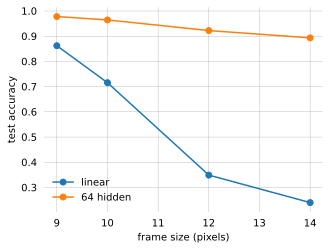

In [26]:
# Solution 4.1
sizes, acc_lin, acc_hid = [9, 10, 12, 14], [], []
for size in sizes:
    rng = np.random.default_rng(1)
    tr = np.vstack([shift_images(img_train, size, rng) for _ in range(4)]).reshape(4*len(img_train), -1)
    te = shift_images(img_test, size, rng).reshape(len(img_test), -1)
    acc_lin.append(accuracy(train(tr, y_train_s, 0,  epochs=100), te, y_test))
    acc_hid.append(accuracy(train(tr, y_train_s, 64, epochs=100), te, y_test))
    print(f"frame {size:2d}x{size:2d}: linear {acc_lin[-1]:.3f}   64 hidden {acc_hid[-1]:.3f}")
plt.plot(sizes, acc_lin, "o-", label="linear"); plt.plot(sizes, acc_hid, "o-", label="64 hidden")
plt.xlabel("frame size (pixels)"); plt.ylabel("test accuracy"); plt.legend(); plt.show()
# Even one pixel of slack (9x9, four positions) costs the linear model a lot; by 12x12
# it is close to useless, while the hidden model degrades slowly.

In [27]:
# Solution 4.2
for copies in [1, 4, 8]:
    rng = np.random.default_rng(1)
    tr = np.vstack([shift_images(img_train, 12, rng) for _ in range(copies)]).reshape(copies*len(img_train), -1)
    ytr = np.tile(y_train, copies)
    te = shift_images(img_test, 12, rng).reshape(len(img_test), -1)
    print(f"{copies} copies: linear {accuracy(train(tr, ytr, 0, epochs=100), te, y_test):.3f}"
          f"   64 hidden {accuracy(train(tr, ytr, 64, epochs=100), te, y_test):.3f}")
# More shifted copies help the hidden model substantially: it gets to see each
# stroke in more positions. The linear model gains a little and then stalls well
# below 40 %, because its problem is not lack of data but lack of expressiveness:
# no single template fits all positions.

1 copies: linear 0.218   64 hidden 0.793
4 copies: linear 0.349   64 hidden 0.922
8 copies: linear 0.338   64 hidden 0.944


In [28]:
# Solution 4.3
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])
for nh in [0, 2, 4]:
    p_ = train(X_xor, y_xor, n_hidden=nh, epochs=3000, lr=0.5, batch=4)
    print(f"{nh} hidden: predictions {predict(p_, X_xor)}   target {y_xor}")
# A linear model draws one straight line through the plane and labels the two
# sides. No single line separates {(0,1),(1,0)} from {(0,0),(1,1)}: the two
# classes sit on the diagonals. Two hidden nodes can each draw a line (e.g.
# "x1+x2 > 0.5" and "x1+x2 > 1.5"), and the output combines them into a band.
# (With 2 hidden nodes training occasionally gets stuck in a local minimum;
# rerun with another seed or use 4.)

0 hidden: predictions [0 0 0 0]   target [0 1 1 0]
2 hidden: predictions [0 1 1 0]   target [0 1 1 0]
4 hidden: predictions [0 1 1 0]   target [0 1 1 0]


In [29]:
# Solution 4.4
def train_relu(X, y, n_hidden=64, epochs=200, lr=0.1, batch=32, seed=0):
    rng = np.random.default_rng(seed); n_in = X.shape[1]; T = np.eye(10)[y]
    W1 = rng.normal(0, np.sqrt(2/n_in), (n_in, n_hidden)); b1 = np.zeros(n_hidden)
    W2 = rng.normal(0, np.sqrt(2/n_hidden), (n_hidden, 10)); b2 = np.zeros(10)
    for epoch in range(epochs):
        order = rng.permutation(len(X))
        for i in range(0, len(X), batch):
            idx = order[i:i+batch]; x, t = X[idx], T[idx]
            z1 = x @ W1 + b1
            h = np.maximum(0, z1)                      # ReLU forward
            p = softmax(h @ W2 + b2)
            dz2 = (p - t) / len(idx)
            dh = dz2 @ W2.T
            dz1 = dh * (z1 > 0)                        # ReLU backward: slope 1 where z>0, else 0
            W2 -= lr * h.T @ dz2; b2 -= lr * dz2.sum(0)
            W1 -= lr * x.T @ dz1; b1 -= lr * dz1.sum(0)
    return W1, b1, W2, b2

def predict_relu(params, X):
    W1, b1, W2, b2 = params
    return softmax(np.maximum(0, X @ W1 + b1) @ W2 + b2).argmax(1)

relu_params = train_relu(Xs_train, y_train_s)
print(f"ReLU, 64 hidden, shifted digits: test {(predict_relu(relu_params, Xs_test) == y_test).mean():.3f}")
# ReLU reaches similar accuracy here. Its derivative is either 0 or 1, so
# gradients do not shrink as they pass through the layer (the sigmoid's slope is
# at most 0.25), which matters much more once networks have several layers. It
# also needs no steepness trick like the one in Part 2C.

ReLU, 64 hidden, shifted digits: test 0.909


## Going further: the full MNIST dataset

Everything above transfers unchanged to the classic 28×28 MNIST digits (70 000 images). The only differences are the shape (784 inputs) and the time per epoch (a few seconds in NumPy). Download it once with scikit-learn and reuse the exact same `train` function, with a larger hidden layer and fewer epochs:

In [30]:
# from sklearn.datasets import fetch_openml
# mnist = fetch_openml("mnist_784", version=1, as_frame=False)
# X = mnist.data / 255.0
# y = mnist.target.astype(int)
# X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]


In [31]:
import urllib.request, os
url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
if not os.path.exists("mnist.npz"):
    urllib.request.urlretrieve(url, "mnist.npz")

with np.load("mnist.npz") as d:
    X_train = d["x_train"].reshape(60000, -1) / 255.0
    y_train = d["y_train"].astype(int)
    X_test  = d["x_test"].reshape(10000, -1) / 255.0
    y_test  = d["y_test"].astype(int)

linear = train(X_train, y_train, n_hidden=0,   epochs=10, lr=0.5)
hidden = train(X_train, y_train, n_hidden=128, epochs=10, lr=0.5)
print(accuracy(linear, X_test, y_test), accuracy(hidden, X_test, y_test))

0.9159 0.977


In [32]:
len(axes.ravel())

10

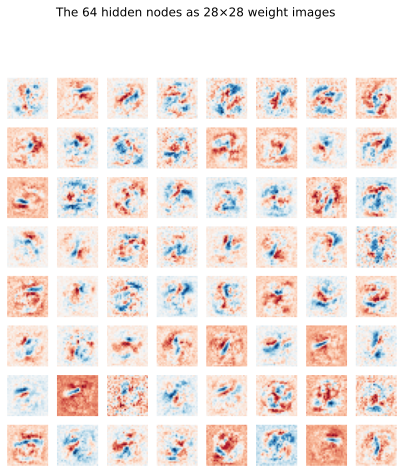

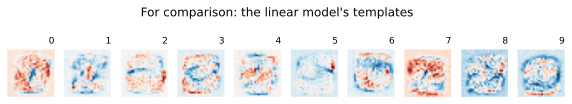

In [45]:
W1 = hidden[0]
fig, axes = plt.subplots(8, 8, figsize=(7, 7))
for j, ax in enumerate(axes.ravel()):
    ax.imshow(W1[:, j].reshape(28, 28), cmap="RdBu_r"); ax.axis("off")
plt.suptitle("The 64 hidden nodes as 28×28 weight images", y=1.02); plt.show()

W_lin = linear[2]
fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for j, ax in enumerate(axes):
    ax.imshow(W_lin[:, j].reshape(28, 28), cmap="RdBu_r"); ax.set_title(j, fontsize=9); ax.axis("off")
plt.suptitle("For comparison: the linear model's templates", y=1.15); plt.show()


Expect roughly 92 % for the linear model and 97–98 % with 128 hidden nodes. On full-size digits the gap is visible even without shifting, because 28×28 handwriting varies far more in shape than the tiny 8×8 digits do. The same experiments as in Parts 3 and 4 (templates, misclassified digits, shifted frames) are worth repeating here; the weight images in particular are much more recognisable at 28×28.

## Summary

- A **gradient** is "nudge a knob, see how the loss changes". The **chain rule** computes it without nudging, by multiplying local derivatives backwards from the loss.
- **Backpropagation** is nothing more than the chain rule applied to every weight, organised so that each layer's gradient reuses the layer above.
- A **step activation** can't be trained because it has no slope; **sigmoid** and **ReLU** fix that.
- A **linear model** is a template matcher. On well-aligned data it can be very good, which is why ~90 % is often easy.
- A **hidden layer** lets the network invent its own features (strokes, edges) and combine them non-linearly, which is what the remaining accuracy needs, and what makes it robust to variation the template can't absorb.

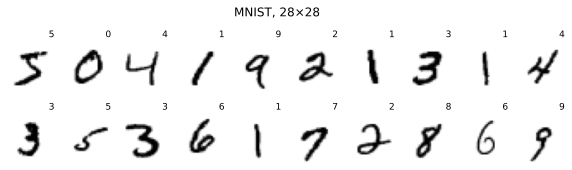

In [34]:
# Full MNIST: training and plots, using the train/predict/accuracy functions
# from the notebook. Paste into the notebook as the "Going further" cells.
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

# ---------- data ----------
url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
if not os.path.exists("mnist.npz"):
    urllib.request.urlretrieve(url, "mnist.npz")
with np.load("mnist.npz") as d:
    img_train, y_train = d["x_train"] / 255.0, d["y_train"].astype(int)
    img_test,  y_test  = d["x_test"]  / 255.0, d["y_test"].astype(int)
X_train = img_train.reshape(len(img_train), -1)      # 60000 x 784
X_test  = img_test.reshape(len(img_test), -1)        # 10000 x 784

fig, axes = plt.subplots(2, 10, figsize=(10, 2.4))
for ax, im, lab in zip(axes.ravel(), img_train, y_train):
    ax.imshow(im, cmap="gray_r"); ax.set_title(lab, fontsize=9); ax.axis("off")
plt.suptitle("MNIST, 28×28", y=1.05); plt.show()


linear model : test 0.9159
128 hidden   : test 0.9770


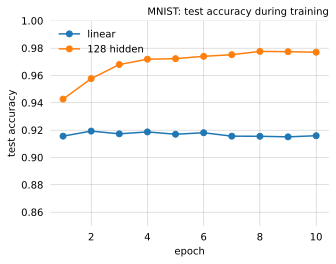

In [35]:

# ---------- train both models ----------
# ~10 epochs is enough; each epoch is a few seconds in NumPy.
linear, hist_lin = train(X_train, y_train, n_hidden=0,   epochs=10, lr=0.5, X_val=X_test, y_val=y_test)
hidden, hist_hid = train(X_train, y_train, n_hidden=128, epochs=10, lr=0.5, X_val=X_test, y_val=y_test)
print(f"linear model : test {accuracy(linear, X_test, y_test):.4f}")
print(f"128 hidden   : test {accuracy(hidden, X_test, y_test):.4f}")

plt.plot(range(1, 11), hist_lin, "o-", label="linear")
plt.plot(range(1, 11), hist_hid, "o-", label="128 hidden")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.ylim(0.85, 1.0); plt.legend()
plt.title("MNIST: test accuracy during training"); plt.show()


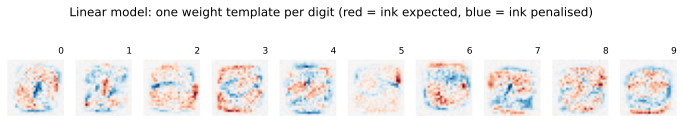

In [46]:

# ---------- the linear model's templates ----------
W = linear[2]
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for j, ax in enumerate(axes):
    v = np.abs(W[:, j]).max()
    ax.imshow(W[:, j].reshape(28, 28), cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(j, fontsize=9); ax.axis("off")
plt.suptitle("Linear model: one weight template per digit (red = ink expected, blue = ink penalised)", y=1.2)
plt.show()


841 linear errors, 230 hidden-model errors, 651 fixed by the hidden layer


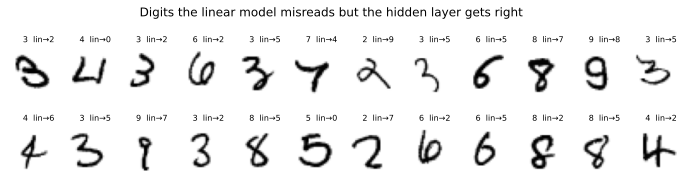

In [37]:

# ---------- what the linear model gets wrong that the hidden model gets right ----------
pred_lin, pred_hid = predict(linear, X_test), predict(hidden, X_test)
fixed = np.where((pred_lin != y_test) & (pred_hid == y_test))[0]
print(f"{(pred_lin != y_test).sum()} linear errors, {(pred_hid != y_test).sum()} hidden-model errors, "
      f"{len(fixed)} fixed by the hidden layer")
fig, axes = plt.subplots(2, 12, figsize=(12, 2.6))
for ax, i in zip(axes.ravel(), fixed[:24]):
    ax.imshow(img_test[i], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"{y_test[i]}  lin→{pred_lin[i]}", fontsize=8)
plt.suptitle("Digits the linear model misreads but the hidden layer gets right", y=1.05); plt.show()


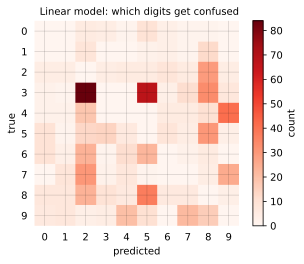

In [38]:

# ---------- confusion matrix of the linear model ----------
conf = np.zeros((10, 10), int)
for t_, p_ in zip(y_test, pred_lin):
    conf[t_, p_] += 1
np.fill_diagonal(conf, 0)                      # hide the correct ones to see the confusions
plt.imshow(conf, cmap="Reds"); plt.colorbar(label="count")
plt.xticks(range(10)); plt.yticks(range(10)); plt.xlabel("predicted"); plt.ylabel("true")
plt.title("Linear model: which digits get confused"); plt.show()


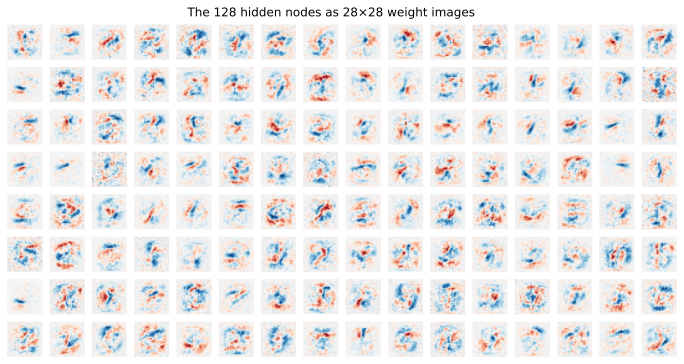

In [52]:

# ---------- the hidden nodes as images ----------
W1 = hidden[0]
fig, axes = plt.subplots(8, 16, figsize=(12, 6))
for j, ax in enumerate(axes.ravel()):
    v = np.abs(W1[:, j]).max()
    ax.imshow(W1[:, j].reshape(28, 28), cmap="RdBu_r", vmin=-v, vmax=v); ax.axis("off")
plt.suptitle("The 128 hidden nodes as 28×28 weight images", y=0.92); plt.show()


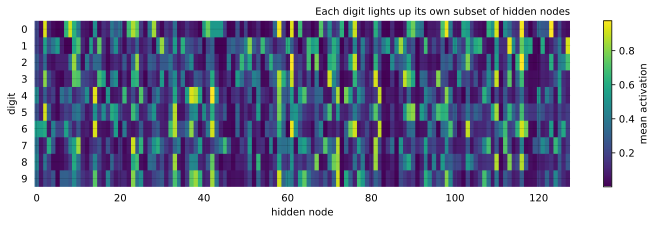

In [40]:

# ---------- which hidden nodes does each digit use? ----------
# Average hidden activation per digit class: the output layer combines these.
W1, b1 = hidden[0], hidden[1]
H = sigmoid(X_test @ W1 + b1)
mean_act = np.array([H[y_test == c].mean(axis=0) for c in range(10)])
plt.figure(figsize=(12, 3))
plt.imshow(mean_act, aspect="auto", cmap="viridis"); plt.colorbar(label="mean activation")
plt.yticks(range(10)); plt.ylabel("digit"); plt.xlabel("hidden node")
plt.title("Each digit lights up its own subset of hidden nodes"); plt.show()